In [2]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [3]:
iris = load_iris()
X = iris.data
y = iris.target
print("Dataset shape:", X.shape)
print("Target shape:", y.shape)
print("Classes:", iris.target_names)

Dataset shape: (150, 4)
Target shape: (150,)
Classes: ['setosa' 'versicolor' 'virginica']


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 120
Testing samples: 30


In [5]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [6]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(4,)),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(8, activation="relu"),
    tf.keras.layers.Dense(3, activation="softmax")
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 16)                  │              80 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 3)                   │              27 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 243 (972.00 B)

 Trainable params: 243 (972.00 B)

 Non-trainable params: 0 (0.00 B)

In [7]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [8]:
history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=8,
    validation_split=0.2
)

Epoch 1/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - accuracy: 0.3646 - loss: 1.1739 - val_accuracy: 0.4167 - val_loss: 1.1205
Epoch 2/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.3854 - loss: 1.1218 - val_accuracy: 0.4167 - val_loss: 1.0902
Epoch 3/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.4167 - loss: 1.0734 - val_accuracy: 0.5000 - val_loss: 1.0646
Epoch 4/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.4896 - loss: 1.0389 - val_accuracy: 0.5000 - val_loss: 1.0460
Epoch 5/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5312 - loss: 1.0120 - val_accuracy: 0.5000 - val_loss: 1.0297
Epoch 6/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5208 - loss: 0.9881 - val_accuracy: 0.4583 - val_loss: 1.0116
Epoch 7/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5104 - loss: 0.9635 - val_accuracy: 0.4583 - val_loss: 0.9900
Epoch 8/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5208 - loss: 0.9362 - val_accuracy: 0.5833 - val_lo

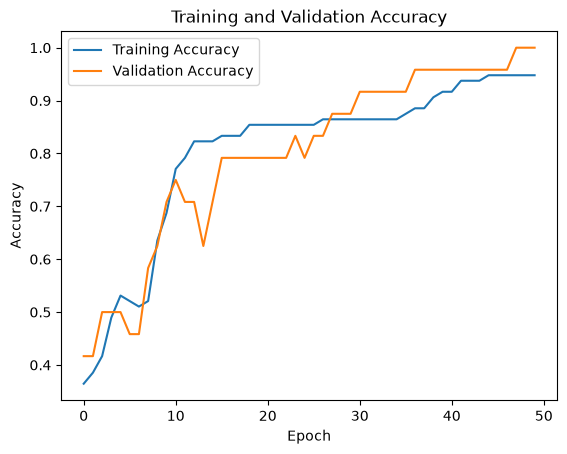

In [9]:
plt.plot(history.history["accuracy"])
plt.plot(history.history["val_accuracy"])
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend(["Training Accuracy", "Validation Accuracy"])
plt.show()

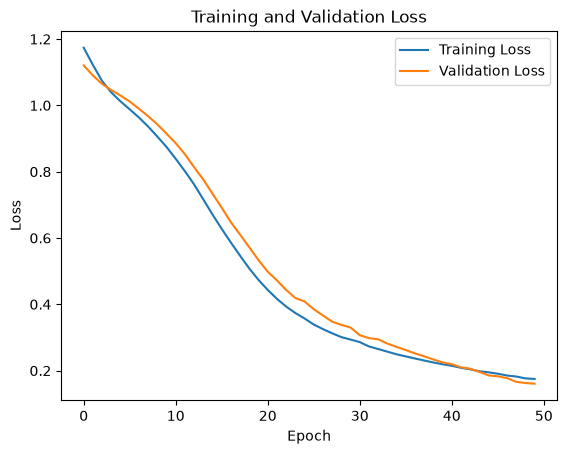

In [10]:
plt.plot(history.history["loss"])
plt.plot(history.history["val_loss"])
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend(["Training Loss", "Validation Loss"])
plt.show()

In [11]:
loss, accuracy = model.evaluate(X_test, y_test)
print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 218ms/step - accuracy: 0.9333 - loss: 0.2066
Test Loss: 0.20657120645046234
Test Accuracy: 0.9333333373069763


In [12]:
probabilities = model.predict(X_test)
predictions = np.argmax(probabilities, axis=1)
print("Predicted:", predictions)
print("Actual:", y_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step
Predicted: [0 2 1 1 0 2 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 2 1 0 2 0]
Actual: [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]


Confusion Matrix:
[[10  0  0]
 [ 0  8  2]
 [ 0  0 10]]


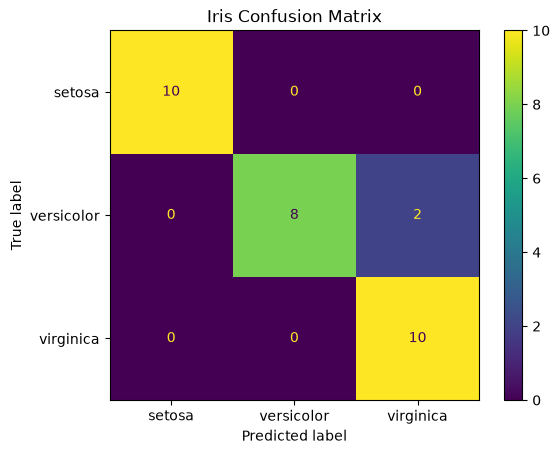

In [13]:
cm = confusion_matrix(y_test, predictions)
print("Confusion Matrix:")
print(cm)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)
disp.plot()
plt.title("Iris Confusion Matrix")
plt.show()

In [14]:
new_flower = np.array([
    [5.1, 3.5, 1.4, 0.2]
])
new_flower = scaler.transform(new_flower)
prediction = model.predict(new_flower)
class_number = np.argmax(prediction)
print("Predicted Flower:", iris.target_names[class_number])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step
Predicted Flower: setosa


In [15]:
model.save("iris_neural_network.keras")
print("Model saved successfully.")

Model saved successfully.


In [16]:
loaded_model = tf.keras.models.load_model(
    "iris_neural_network.keras"
)
print("Model loaded successfully.")

Model loaded successfully.


In [18]:
prediction = loaded_model.predict(new_flower)

class_number = np.argmax(prediction)

print("Prediction:", iris.target_names[class_number])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
Prediction: setosa
